# 07 — Feature families, modern measurements and interactions

**Objective.** Assess whether removing a feature family changes validation performance and whether two prespecified workload interactions help.

**Cohort and interpretation.** 30-day elbow/UCL, shoulder, forearm and lower-body comparisons. Every variant uses the same chronological training/validation rows and train-only preprocessing. Family ablations and interactions are **validation-only**; the test set is not used to choose a winner. Correlated families make coefficient magnitudes and removal effects conditional, not causal.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config/injury_analysis.yaml").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.injury_analysis.common import CFG, CACHE, OUT, read_table, table, conclusion, style
from src.injury_analysis.cohort import load
from src.injury_analysis import plots
style()
pd.set_option('display.max_columns', 14)


Completed validation-only family comparisons: Elbow / UCL


Completed validation-only family comparisons: Shoulder


Completed validation-only family comparisons: Forearm


Completed validation-only family comparisons: Lower body


,predictors
family,
command,8
extension,4
pitch_mix,6
pitcher_history,7
release_mechanics,8
spin_movement,7
velocity,7
workload,15


,category,variant,predictors,events,average_precision,ap_change_vs_all
0,Elbow / UCL,All selected,62,89,0.028254,0.000000
1,Elbow / UCL,With two interactions,64,89,0.028264,0.000010
2,Elbow / UCL,Without command,54,89,0.028214,-0.000040
3,Elbow / UCL,Without extension,58,89,0.028000,-0.000254
4,Elbow / UCL,Without pitch_mix,56,89,0.031574,0.003320
5,Elbow / UCL,Without pitcher_history,55,89,0.024929,-0.003325
6,Elbow / UCL,Without release_mechanics,54,89,0.031963,0.003708
7,Elbow / UCL,Without spin_movement,55,89,0.027380,-0.000875
8,Elbow / UCL,Without velocity,55,89,0.027229,-0.001026
9,Elbow / UCL,Without workload,47,89,0.028249,-0.000005


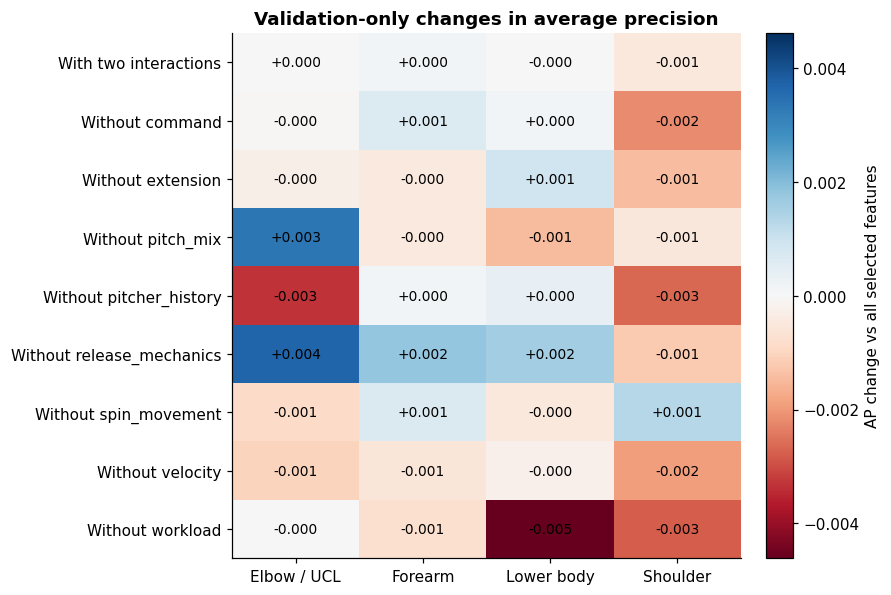

In [2]:
from src.injury_analysis.prediction import run_family_analysis
a, events, spec = load()
family = run_family_analysis(a, spec)
display(spec[spec.selected_for_prediction].groupby('family').agg(predictors=('name','size')))
display(family[['category','variant','predictors','events','average_precision','ap_change_vs_all']])
plots.family_figure(); plt.show()

## Interpretation and the modern-feature era
Interactions are velocity z-score × recent workload acceleration, and release-variability z-score × workload acceleration. They are known after the outing and cannot include future injury or recovery information. An ablation can improve AP when a correlated/noisy family is removed; this is not a definitive estimate of biological relevance.

Arm-angle features are excluded from this long-history model. Their matched event effects below use only pairs with nonmissing measurements in the same season. No historical zeros are substituted. Within-game velocity decline requires disjoint 20-fastball segments and is sparse among relievers. Existing full feature tables preserve both for later focused studies.

In [3]:
availability=read_table('feature_availability_by_season')
display(availability[availability.feature.isin(['arm_angle_avg','arm_angle_z','velo_drop_game'])].pivot(index='season',columns='feature',values='available_fraction'))
effects=read_table('paired_preinjury_effects')
display(effects[effects.feature.eq('arm_angle_z')])
coef=read_table('model_coefficients')
display(coef[coef.category.eq('Elbow / UCL')].assign(magnitude=lambda d:d.standardized_log_odds.abs()).nlargest(12,'magnitude').drop(columns='magnitude'))
inter=family[family.variant.eq('With two interactions')]
conclusion(f"Removing feature families or adding the two interactions changes validation AP by {family.ap_change_vs_all.min():+.4f} to {family.ap_change_vs_all.max():+.4f}. The interaction changes range from {inter.ap_change_vs_all.min():+.4f} to {inter.ap_change_vs_all.max():+.4f}. These single-split comparisons identify follow-up hypotheses, not a final selected feature set; arm-angle evidence uses a smaller modern-era sample.")

feature,arm_angle_avg,arm_angle_z,velo_drop_game
season,,,
2015,0.000000,0.000000,0.224078
2016,0.000000,0.000000,0.218309
2017,0.000000,0.000000,0.209961
2018,0.000000,0.000000,0.198088
2019,0.000000,0.000000,0.185529
2020,0.778352,0.405324,0.157689
2021,0.978794,0.909815,0.167226
2022,0.995759,0.952672,0.173020
2023,0.995126,0.956130,0.176602


,analysis_group,feature,mean,low,high,n,pitchers
8,Elbow / UCL,arm_angle_z,0.168435,-0.105331,0.435850,134,126
17,Forearm,arm_angle_z,0.161941,-0.308883,0.520302,55,53
26,Hand / wrist,arm_angle_z,-0.452993,-0.802313,-0.052597,39,34
35,Lower body,arm_angle_z,0.242911,0.017517,0.481941,153,134
44,Other arm,arm_angle_z,0.253180,-0.156502,0.697829,48,46
53,Shoulder,arm_angle_z,0.010494,-0.274379,0.280307,142,129
62,Trunk / neck,arm_angle_z,-0.218485,-0.479690,0.035773,98,92


,category,feature,standardized_log_odds
56,Elbow / UCL,throws_left,0.466995
7,Elbow / UCL,release_x_avg,-0.441787
41,Elbow / UCL,innings_pitched,-0.438277
59,Elbow / UCL,is_starter,0.303934
46,Elbow / UCL,appearances_prev_14d,-0.259482
94,Elbow / UCL,missingindicator_rest_days,-0.244381
4,Elbow / UCL,velo_z,-0.230467
26,Elbow / UCL,fastball_usage_pct,-0.227394
23,Elbow / UCL,vertical_movement_avg,0.224709
61,Elbow / UCL,calendar_month,0.221398


**Computed conclusion.** Removing feature families or adding the two interactions changes validation AP by -0.0046 to +0.0037. The interaction changes range from -0.0005 to +0.0001. These single-split comparisons identify follow-up hypotheses, not a final selected feature set; arm-angle evidence uses a smaller modern-era sample.